## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [1]:
import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

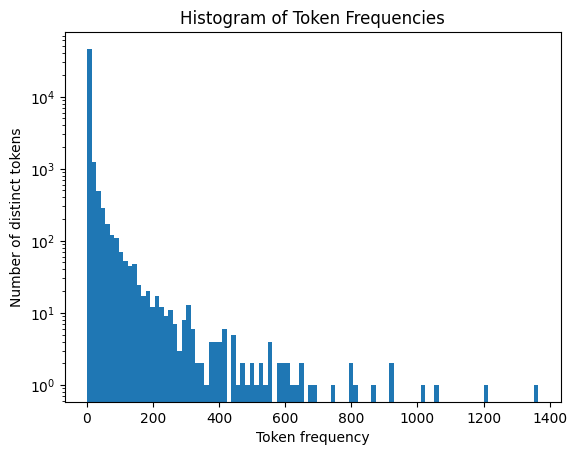

In [2]:
import matplotlib.pyplot as plt

counts = list(token_count.values())

plt.hist(counts, bins=100, log=True)
plt.xlabel('Token frequency')
plt.ylabel('Number of distinct tokens')
plt.title('Histogram of Token Frequencies')
plt.show()

There are many tokens that are only seen a few times, while there is a much smaller number that is shown upwards of 1200 times. The distribution is skewed right with a long tail.

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_parquet('Phishing_clean.parquet')

y = df['Email Type']
X = df.drop(columns='Email Type')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape, X_test.shape)

from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print(model.score(X_train, y_train))
print(model.score(X_test, y_test))

(14907, 2711) (3727, 2711)
0.7670143724934355
0.6658718438847919


In [4]:
coefs = pd.Series(model.coef_, index=X.columns)

top = coefs.reindex(coefs.abs().sort_values(ascending=False).index)
print(top.head(15))

intervention        -1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:   -0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;               -0.574480
a:active             0.574480
retrieving          -0.573761
zdnet               -0.560954
{text-decoration:    0.497075
xanaax               0.491981
transcript           0.488978
dtype: float64


The R^2 is 0.767 on the training set and 0.666 on the test set


The words with the biggest coefficients are intervention at -1.26, localized at 0.82, and thermal at 0.75, and crawler (0.70). Positive coefficients mean that the email looks like a scam, negative means it looks real. But these words are rare (intervention is in only 56 of 18,634 emails), so their coefficients are based on very little data and can be large and unreliable. This fits with overfitting, which also shows in the gap between the train R^2 of 0.77 and the test R^2 of 0.67).

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

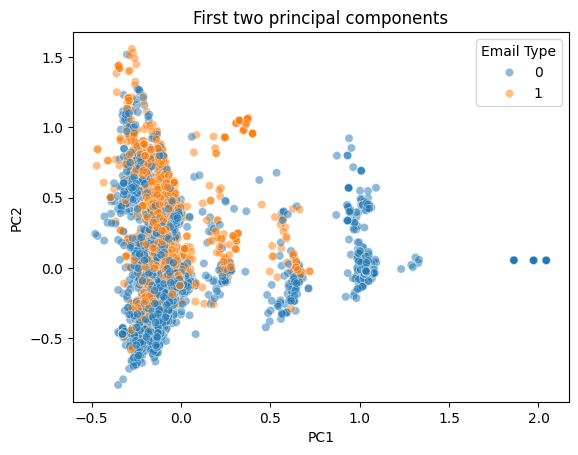

[0.01113089 0.00861061]


In [5]:
from sklearn.decomposition import PCA
import seaborn as sns

pca = PCA(n_components=2)
Z = pca.fit_transform(X.astype(float))

sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=y, alpha=0.5)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('First two principal components')
plt.show()

print(pca.explained_variance_ratio_)

The PCA plot shows significant overlap between scam and real emails. Most points sit in one dense cluster, and the first two components don't cleanly separate the classes. They also explain very little of the variance, only ~1.1% and ~0.9%, because the information is spread across 2,711 features.

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

In [6]:
from sklearn.linear_model import LinearRegression

pca2 = PCA(n_components=2610)
Z_train = pca2.fit_transform(X_train.astype(float))
Z_test = pca2.transform(X_test.astype(float))

model_pca = LinearRegression()
model_pca.fit(Z_train, y_train)

print('Train R^2:', model_pca.score(Z_train, y_train))
print('Test R^2: ', model_pca.score(Z_test, y_test))

Train R^2: 0.7662326827745849
Test R^2:  0.6683390643101164


The regression on 2,610 principal components has an R^2 of 0.766 on the training set and 0.668 on the test set, nearly the same as the original regression: 0.767 on train and 0.666 for the test. This makes sense because 2,610 components keep almost all of the information in the 2,711 original features.

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

PCA allows the regression use fewer and cleaner features. The original data has 2,711 word columns, many of which are rare or correlated, and in turn makes the regression unstable and prone to overfitting; for exmaple, this can be seen in the gap between train R^2 of 0.77 and test R^2 of 0.67. PCA turns the data into uncorrelated features ordered by how much variation they capture, allowing us to drop the low variance ones. That means there are fewer coefficients to estimate and therefore a simpler and more stable model.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Olympia Sauerwein

**Date:** October 21st

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [7]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]